# 11 · Помогает ли больше обучающих данных?

**Вопрос:** улучшает ли расширение обучающей выборки результат при той же модели и тех же признаках?

Модель – Ridge с поправкой к линейной интерполяции. Добавляем изученные рейсы 28 октября и три новые даты ноября. Выбор регуляризации – 25 ноября, проверка – **2 декабря 2019 года**. Порядок добавления данных и даты зафиксированы до расчета ошибок.

Сравниваем исходную модель 08, модель на тех же шести train-рейсах с регуляризацией по новой validation-дате и расширенную модель с той же процедурой выбора. Это позволяет отличить влияние данных от влияния повторного выбора регуляризации. Дополнительно проверяем интерполяцию Эрмита, которая использует позиции и скорости обоих концов без обучения.

In [1]:
# Загружаем план дат и фиксируем целостность старой модели
from pathlib import Path
import contextlib
import io
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display, Markdown
root = next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'research/c40_geometry').is_dir())
study = root/'research/c40_geometry'
sys.path.insert(0,str(study/'scripts'))
from evaluate_hidden_points import main as evaluate_baselines
from audit_c40_radial_cases import ellipsoid_distance
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib','inline')
plt.rcParams.update({'figure.dpi':120,'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
plan = json.loads((study/'reports/11_expanded_protocol.json').read_text(encoding='utf8'))
old_model_path = study/'data/public_pilot/08_ridge_model.npz'
assert hashlib.sha256(old_model_path.read_bytes()).hexdigest() == plan['old_model_sha256']
old_model = np.load(old_model_path,allow_pickle=False)
old_split = json.loads((study/'reports/08_ml_protocol.json').read_text(encoding='utf8'))['split']
small_flights = [f for f,part in old_split.items() if part == 'train']
assert len(small_flights) == 6
display(plan)

{'version': '11-v1',
 'train_days': ['2019-11-04', '2019-11-11', '2019-11-18'],
 'validation_day': '2019-11-25',
 'test_day': '2019-12-02',
 'existing_train': 'six train flights from 08 plus all ten flights from inspected 10',
 'selection': 'first 30 chronological eligible EGCC/EPWA cases, hour 22 UTC',
 'alphas': [0.1, 1.0, 10.0, 100.0, 1000.0],
 'comparison': 'same Ridge features; old 08, six-flight refit, expanded refit; one new test day',
 'old_model_sha256': '595cbe06edbf32c7fdcc83f3914be436b60978d0468e2df0e0230f60ee92443b'}

## 1. Собираем данные разных дат и повторяем правила 07

Каждая дата хранится в своей локальной папке. Проверяем SHA256 подготовленной последовательности и ее календарную дату. Берем все найденные заранее выбранные рейсы; пропавшие случаи не заменяем по результатам модели. Аналитическая база лишь задает рейсы и временные окна; восстановление оценивается по наблюдениям OpenSky.

Прежние validation/test-рейсы из 08 в обучение не добавляем. День 28 октября уже изучен в 10 и теперь явно становится обучающим. Для нового test выделена другая дата.

In [2]:
# Формируем список источников с заранее назначенными ролями
datasets = [
    ('2019-10-21','train',study/'data/public_pilot/EPWA_control_geometry.csv',
     study/'data/public_pilot/07_hidden_point_errors.csv',None),
    ('2019-10-28','train',study/'data/external_day/external_geometry.csv',
     study/'data/external_day/10_external_hidden_point_errors.csv','10_external')]
for day in plan['train_days']+[plan['validation_day'],plan['test_day']]:
    part = 'train' if day in plan['train_days'] else ('validation' if day == plan['validation_day'] else 'test')
    folder = study/f'data/expanded_training/{day}'
    datasets.append((day,part,folder/'external_geometry.csv',folder/f'11_{day}_hidden_point_errors.csv','11_'+day))
frames, baseline_frames, provenance = [], [], []
split, flight_day = {}, {}
for day,part,path,error_path,prefix in datasets:
    frame = pd.read_csv(path)
    if day == '2019-10-21':
        frame = frame[frame.case_flight_id.isin(small_flights)].copy()
        old_audit = json.loads((study/'reports/07_hidden_point_audit.json').read_text(encoding='utf8'))
        assert hashlib.sha256(path.read_bytes()).hexdigest() == old_audit['source_sha256']
    else:
        manifest = json.loads((study/f'reports/{prefix}_download.json').read_text(encoding='utf8'))
        assert hashlib.sha256(path.read_bytes()).hexdigest() == manifest['selected_sha256']
    assert pd.to_datetime(frame.time,unit='s',utc=True).dt.strftime('%Y-%m-%d').eq(day).all()
    # Для новых дат применяем неизменные интервалы и критерии пригодности
    if day in plan['train_days']+[plan['validation_day'],plan['test_day']]:
        if not error_path.exists() or not (study/f'reports/{prefix}_hidden_point_audit.json').exists():
            with contextlib.redirect_stdout(io.StringIO()):
                evaluate_baselines(path,prefix=prefix)
        cached = json.loads((study/f'reports/{prefix}_hidden_point_audit.json').read_text(encoding='utf8'))
        assert cached['source_sha256'] == hashlib.sha256(path.read_bytes()).hexdigest()
        assert cached['gaps_s'] == [20,30,60,120] and cached['max_position_age_s'] == 2
    errors = pd.read_csv(error_path)
    errors = errors[errors.flight_id.isin(frame.case_flight_id.unique())].copy()
    for flight in frame.case_flight_id.unique():
        assert flight not in split, 'Повтор идентификатора между датами'
        split[flight],flight_day[flight] = part,day
    frames.append(frame)
    baseline_frames.append(errors)
    provenance.append({'Дата':day,'Часть':part,'Рейсов':frame.case_flight_id.nunique(),
                       'Наблюдений':len(frame),'Целей':len(errors)//3})
source = pd.concat(frames,ignore_index=True)
baseline_errors = pd.concat(baseline_frames,ignore_index=True)
display(pd.DataFrame(provenance))
# Проверяем непересечение дат обучения, выбора модели и проверки
assert not set(plan['train_days']+['2019-10-21','2019-10-28']).intersection([plan['validation_day'],plan['test_day']])

,Дата,Часть,Рейсов,Наблюдений,Целей
0,2019-10-21,train,6,753,11277
1,2019-10-28,train,10,1359,21727
2,2019-11-04,train,7,920,14452
3,2019-11-11,train,6,767,11999
4,2019-11-18,train,12,1442,22419
5,2019-11-25,validation,8,935,14581
6,2019-12-02,test,9,1151,17439


## 2. Формируем неизменные признаки

Используем код признаков 08. Скрытые координаты входят только в проверочный ответ. Каждому рейсу назначена одна часть. Все методы далее оцениваются на одной и той же подвыборке целей с конечными признаками.

In [3]:
# Берем точно те же цели, которые сравнивались в эксперименте 07
key = ['flight_id','gap_s','left_time','target_time']
tasks = baseline_errors[baseline_errors.method.eq('linear_lat_lon')][key].copy()
assert not tasks.duplicated(key).any()
observed = source.rename(columns={'case_flight_id':'flight_id'})
assert not observed.duplicated(['flight_id','time']).any()
tasks['right_time'] = tasks.left_time+tasks.gap_s
# Присоединяем доступные концы отдельно от скрытого ответа
for role,time_col in [('a','left_time'),('b','right_time'),('target','target_time')]:
    fields = ['flight_id','time','lat','lon']
    if role != 'target':
        fields += ['velocity','heading','lastposupdate']
    renamed = observed[fields].rename(columns={c:f'{role}_{c}' for c in fields if c != 'flight_id'})
    tasks = tasks.merge(renamed,left_on=['flight_id',time_col],right_on=['flight_id',f'{role}_time'],validate='many_to_one')
tasks['part'] = tasks.flight_id.map(split)
w = (tasks.target_time-tasks.left_time)/tasks.gap_s
duration = tasks.gap_s
# Линейная интерполяция определяется только доступными концами
lon_delta = (tasks.b_lon-tasks.a_lon+180)%360-180
linear_lat = tasks.a_lat+w*(tasks.b_lat-tasks.a_lat)
linear_lon = tasks.a_lon+w*lon_delta
east_scale = 111320*np.cos(np.radians((tasks.a_lat+tasks.b_lat)/2))
north_scale = 111200
east = lon_delta*east_scale
north = (tasks.b_lat-tasks.a_lat)*north_scale
ha,hb = np.radians(tasks.a_heading),np.radians(tasks.b_heading)
va_e,va_n = tasks.a_velocity*np.sin(ha),tasks.a_velocity*np.cos(ha)
vb_e,vb_n = tasks.b_velocity*np.sin(hb),tasks.b_velocity*np.cos(hb)
curve = w*(1-w)*duration
# Кинематические подсказки используют только скорость и направление концов
features = pd.DataFrame({'gap_s':duration,'fraction':w,'curve_time_s':curve,
    'speed_a':tasks.a_velocity,'speed_b':tasks.b_velocity,
    'heading_a_sin':np.sin(ha),'heading_a_cos':np.cos(ha),
    'heading_b_sin':np.sin(hb),'heading_b_cos':np.cos(hb),
    'age_a':tasks.a_time-tasks.a_lastposupdate,'age_b':tasks.b_time-tasks.b_lastposupdate,
    'east_span':east,'north_span':north,
    'forward_residual_e':va_e*w*duration-w*east,
    'forward_residual_n':va_n*w*duration-w*north,
    'backward_residual_e':(1-w)*east-vb_e*(1-w)*duration,
    'backward_residual_n':(1-w)*north-vb_n*(1-w)*duration,
    'velocity_change_e':(vb_e-va_e)*curve,'velocity_change_n':(vb_n-va_n)*curve})
# Координаты скрытых точек появляются только в целевой поправке
target = np.column_stack([((tasks.target_lon-linear_lon+180)%360-180)*east_scale,
                          (tasks.target_lat-linear_lat)*north_scale])
usable = np.isfinite(features).all(axis=1) & np.isfinite(target).all(axis=1)
display(tasks.assign(usable=usable).groupby('part').agg(total=('flight_id','size'),usable=('usable','sum')))
# Сравниваем все методы на общей подвыборке при наличии пропусков признаков
tasks = tasks.loc[usable].reset_index(drop=True)
features = features.loc[usable].reset_index(drop=True)
target = target[usable]
linear_lat = linear_lat.loc[usable].to_numpy()
linear_lon = linear_lon.loc[usable].to_numpy()
east_scale = east_scale.loc[usable].to_numpy()
assert set(tasks.flight_id) == set(split)
display(features.head().round(3))
display(tasks.groupby(['part','flight_id']).size().rename('Число задач'))

,total,usable
part,,
test,17439,17439
train,81874,81874
validation,14581,14581


,gap_s,fraction,curve_time_s,speed_a,speed_b,heading_a_sin,heading_a_cos,heading_b_sin,heading_b_cos,age_a,age_b,east_span,north_span,forward_residual_e,forward_residual_n,backward_residual_e,backward_residual_n,velocity_change_e,velocity_change_n
0,20,0.5,5.0,208.493,207.998,0.999,-0.037,0.999,-0.040,0.218,0.007,4212.726,-163.063,-22.865,4.365,28.009,0.779,-2.572,-2.572
1,20,0.5,5.0,208.512,207.998,0.999,-0.039,0.999,-0.040,0.155,0.068,4170.851,-161.683,-1.927,-1.470,7.072,1.470,-2.572,0.000
2,20,0.5,5.0,207.998,207.998,0.999,-0.040,0.999,-0.040,0.007,0.009,4143.005,-162.891,6.851,-0.866,-6.851,0.866,0.000,0.000
3,20,0.5,5.0,207.998,207.998,0.999,-0.040,0.999,-0.040,0.068,0.175,4143.073,-162.891,6.817,-0.866,-6.817,0.866,0.000,0.000
4,20,0.5,5.0,207.998,208.019,0.999,-0.040,0.999,-0.042,0.009,0.194,4084.477,-165.824,36.115,0.601,-36.115,4.543,0.000,-2.572


part        flight_id    
test        BEL7AW_9080      2186
            DLH5XK_3215      1882
            DLH9CK_5266      2148
            EZY61VB_38193    2367
            EZY69ME_16265    1748
            EZY83KB_22882    1795
            RYR2WF_65796     1484
            RYR4117_61350    1719
            SAS2761_51223    2110
train       BEL2UQ_43904     2186
            DLH4TW_5877      1844
            DLH4TW_6599      1844
            DLH4TW_6924      2091
            DLH948_5597      2338
            DLH9CK_5423      1958
            DLH9CK_6071      1939
            DLH9CK_6404      2167
            ENT73JH_21100    1731
            EXS4112_71377    2054
            EXS4TQ_30203     2775
            EXS92K_22219     1504
            EZY14WF_22790    1791
            EZY16KQ_14918    1863
            EZY16KQ_16238    1711
            EZY16KQ_19577    1996
            EZY1920_18428    1788
            EZY1942_18429    1977
            EZY34MD_21230    1882
            EZY61VB_21

## 3. Измеряем влияние объема обучения на validation

Стандартизация оценивается на текущей обучающей подвыборке. Каждый рейс имеет одинаковый суммарный вес. Для каждой ступени выбираем регуляризацию по средней рейсовой ошибке 25 ноября из одинакового заранее заданного списка.

Ступени добавляют целые даты в зафиксированном порядке. Это описательная кривая, а не случайные независимые повторы. Большая выборка не гарантирует монотонного улучшения. Итоговую модель заранее определяем как модель на всех обучающих датах, не выбираем ступень по test.

,stage,train_flights,train_tasks,alpha,validation_mean_m
0,0,6,11277,100.0,127.948
1,1,16,33004,100.0,123.344
2,2,23,47456,1000.0,123.105
3,3,29,59455,1000.0,122.651
4,4,41,81874,1000.0,122.175


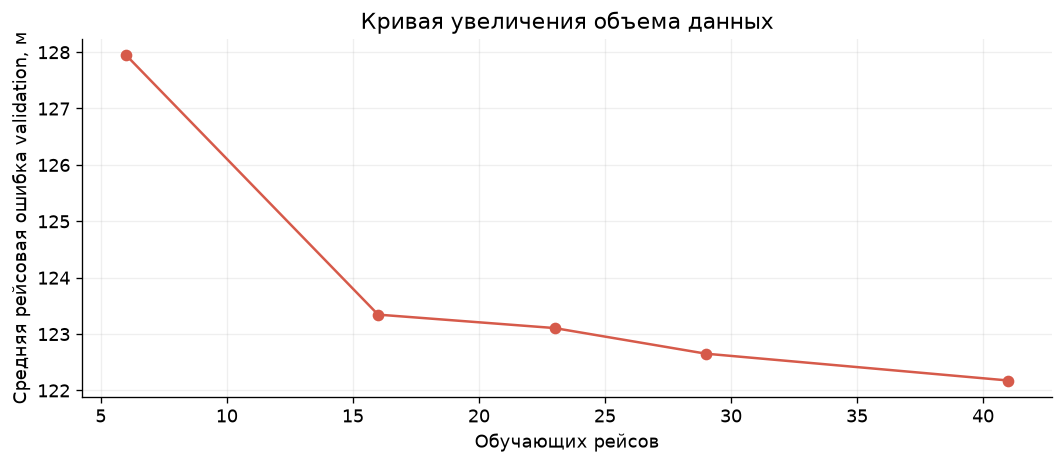

In [4]:
train_mask = tasks.part.eq('train').to_numpy()
val_mask = tasks.part.eq('validation').to_numpy()
test_mask = tasks.part.eq('test').to_numpy()
assert set(tasks.loc[test_mask,'flight_id']).isdisjoint(tasks.loc[train_mask | val_mask,'flight_id'])

# Ошибка поправки вычисляется на эллипсоиде, одинаково для всех моделей
def correction_error(mask, correction):
    return 1000*ellipsoid_distance(tasks.loc[mask,'target_lat'].to_numpy(),tasks.loc[mask,'target_lon'].to_numpy(),
        linear_lat[mask]+correction[:,1]/north_scale,linear_lon[mask]+correction[:,0]/east_scale[mask])

def macro_mean(mask,error):
    return pd.DataFrame({'flight_id':tasks.loc[mask,'flight_id'].to_numpy(),'error':error}).groupby('flight_id').error.mean().mean()

def fit_ridge(mask, alpha):
    mean = features.loc[mask].mean().to_numpy()
    scale = features.loc[mask].std(ddof=0).to_numpy(copy=True)
    scale[scale < 1e-12] = 1
    x = np.column_stack([np.ones(len(features)),(features.to_numpy()-mean)/scale])
    a = x[mask]
    counts = tasks.loc[mask].groupby('flight_id').size()
    weights = tasks.loc[mask,'flight_id'].map(1/counts).to_numpy(copy=True)
    weights *= len(weights)/weights.sum()
    penalty = np.eye(a.shape[1])*alpha
    penalty[0,0] = 0
    coef = np.linalg.solve(a.T@(weights[:,None]*a)+penalty,a.T@(weights[:,None]*target[mask]))
    return {'mean':mean,'scale':scale,'coef':coef,'alpha':alpha},x

# Проверяем, что тот же код на прежних шести рейсах воспроизводит модель 08
original_mask = train_mask & tasks.flight_id.isin(small_flights).to_numpy()
reproduced, _ = fit_ridge(original_mask,float(old_model['alpha']))
assert np.allclose(reproduced['mean'],old_model['mean'])
assert np.allclose(reproduced['scale'],old_model['scale'])
assert np.allclose(reproduced['coef'],old_model['coef'],atol=1e-6,rtol=1e-6)
stage_days = [['2019-10-21'],['2019-10-21','2019-10-28']]
for i in range(len(plan['train_days'])):
    stage_days.append(['2019-10-21','2019-10-28']+plan['train_days'][:i+1])
selection, curve, models = [], [], []
for stage,days in enumerate(stage_days):
    mask = train_mask & tasks.flight_id.map(flight_day).isin(days).to_numpy()
    candidates = []
    for alpha in plan['alphas']:
        model,x = fit_ridge(mask,alpha)
        score = macro_mean(val_mask,correction_error(val_mask,x[val_mask]@model['coef']))
        candidates.append((score,alpha,model))
        selection.append({'stage':stage,'alpha':alpha,'validation_mean_m':score})
    score,alpha,model = min(candidates,key=lambda item:(item[0],item[1]))
    models.append(model)
    curve.append({'stage':stage,'train_flights':tasks.loc[mask,'flight_id'].nunique(),
                  'train_tasks':int(mask.sum()),'alpha':alpha,'validation_mean_m':score})
curve = pd.DataFrame(curve)
display(curve.round(3))
fig,ax = plt.subplots(figsize=(9,4))
ax.plot(curve.train_flights,curve.validation_mean_m,'o-',color='#D65A4A')
ax.set(xlabel='Обучающих рейсов',ylabel='Средняя рейсовая ошибка validation, м',title='Кривая увеличения объема данных')
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()
# Сохраняем окончательную модель до просмотра нового test
final_model = models[-1]
np.savez(study/'data/expanded_training/11_ridge_model.npz',**final_model,
         feature_names=features.columns.to_numpy(dtype=str))
pd.DataFrame(selection).to_csv(study/'reports/11_validation_selection.csv',index=False)
curve.to_csv(study/'reports/11_learning_curve.csv',index=False)

## 4. Открываем новую дату проверки

Сравниваем исходную модель 08, модель на шести рейсах с новой validation и модель на всех обучающих датах. Коэффициенты старой модели не менялись. Сильный простой ориентир – кубическая интерполяция Эрмита: она согласует позиции и горизонтальные скорости обоих концов, но может давать выбросы при несогласованных наблюдениях.

Все ошибки считаются на общих целях test. Для длины пропуска показываем отдельные показатели: общий результат может скрывать ухудшение коротких интервалов.

In [5]:
# Применяем каждую зафиксированную модель к одним проверочным целям
def predict(model, mask):
    x = np.column_stack([np.ones(int(mask.sum())),(features.loc[mask].to_numpy()-model['mean'])/model['scale']])
    return x@model['coef']
assert list(features.columns) == old_model['feature_names'].tolist()
predictions = {'ridge_08':predict(old_model,test_mask),
               'ridge_six_new_validation':predict(models[0],test_mask),
               'ridge_expanded':predict(final_model,test_mask)}
# Эрмит использует только доступные концы и их горизонтальные скорости
wt = ((tasks.target_time-tasks.left_time)/tasks.gap_s).to_numpy()
dt = tasks.gap_s.to_numpy()
span_e = ((tasks.b_lon-tasks.a_lon+180)%360-180).to_numpy()*east_scale
span_n = (tasks.b_lat-tasks.a_lat).to_numpy()*north_scale
ha,hb = np.radians(tasks.a_heading),np.radians(tasks.b_heading)
h01 = -2*wt**3+3*wt**2
h10 = wt**3-2*wt**2+wt
h11 = wt**3-wt**2
hermite = np.column_stack([
    (h01-wt)*span_e+h10*dt*tasks.a_velocity*np.sin(ha)+h11*dt*tasks.b_velocity*np.sin(hb),
    (h01-wt)*span_n+h10*dt*tasks.a_velocity*np.cos(ha)+h11*dt*tasks.b_velocity*np.cos(hb)])
predictions['hermite'] = hermite[test_mask]
test_tasks = tasks.loc[test_mask,key].copy()
evaluation = baseline_errors.merge(test_tasks,on=key,how='inner',validate='many_to_one')
for method,correction in predictions.items():
    rows = test_tasks.copy()
    rows['method'],rows['error_m'] = method,correction_error(test_mask,correction)
    evaluation = pd.concat([evaluation,rows],ignore_index=True)
assert evaluation.groupby(key).method.nunique().eq(7).all()
assert np.isfinite(evaluation.error_m).all()
summary = evaluation.groupby(['flight_id','method']).error_m.agg(
    targets='size',mean_m='mean',median_m='median',p95_m=lambda s:s.quantile(.95),max_m='max').reset_index()
macro = summary.groupby('method')[['mean_m','median_m','p95_m']].mean()
display(macro.round(2))
display(summary.round(2))
by_gap = evaluation.groupby(['flight_id','gap_s','method']).error_m.mean().reset_index()
gap = by_gap.groupby(['gap_s','method']).error_m.mean().unstack()
display(gap.round(2))

,mean_m,median_m,p95_m
method,,,
constant_velocity_sphere,686.65,150.14,3359.94
hermite,124.84,53.54,538.20
linear_lat_lon,356.14,136.87,1565.15
nearest,3430.17,2607.69,8695.55
ridge_08,148.61,73.57,588.35
ridge_expanded,141.07,64.28,591.53
ridge_six_new_validation,148.61,73.57,588.35


,flight_id,method,targets,mean_m,median_m,p95_m,max_m
0,BEL7AW_9080,constant_velocity_sphere,2186,753.21,181.53,3790.57,14595.86
1,BEL7AW_9080,hermite,2186,124.88,54.35,567.61,1707.54
2,BEL7AW_9080,linear_lat_lon,2186,381.95,147.56,1740.23,4279.00
3,BEL7AW_9080,nearest,2186,3859.22,2917.53,9805.19,15025.53
4,BEL7AW_9080,ridge_08,2186,151.79,72.70,639.25,1674.70
...,...,...,...,...,...,...,...
58,SAS2761_51223,linear_lat_lon,2110,405.58,167.07,1972.87,3240.11
59,SAS2761_51223,nearest,2110,3917.52,2631.24,10586.88,15790.35
60,SAS2761_51223,ridge_08,2110,122.11,63.51,460.73,838.85
61,SAS2761_51223,ridge_expanded,2110,119.55,57.55,490.96,838.17


method,constant_velocity_sphere,hermite,linear_lat_lon,nearest,ridge_08,ridge_expanded,ridge_six_new_validation
gap_s,,,,,,,
20,57.13,33.63,47.52,1390.87,51.42,43.29,51.42
30,91.28,37.61,66.21,1383.73,53.97,46.47,53.97
60,288.53,62.78,165.69,2496.89,77.71,71.24,77.71
120,1074.13,183.37,543.48,4531.44,213.66,205.66,213.66


## 5. Что дали дополнительные данные?

Зеленый показывает линейный метод, серый – исходную модель 08, красный – расширенную модель, фиолетовый – Эрмит. Вывод строится из фактической ошибки; больше данных может улучшить, оставить прежним или ухудшить результат. Две модели с одинаковой новой validation дают наиболее прямое сравнение объема обучения.

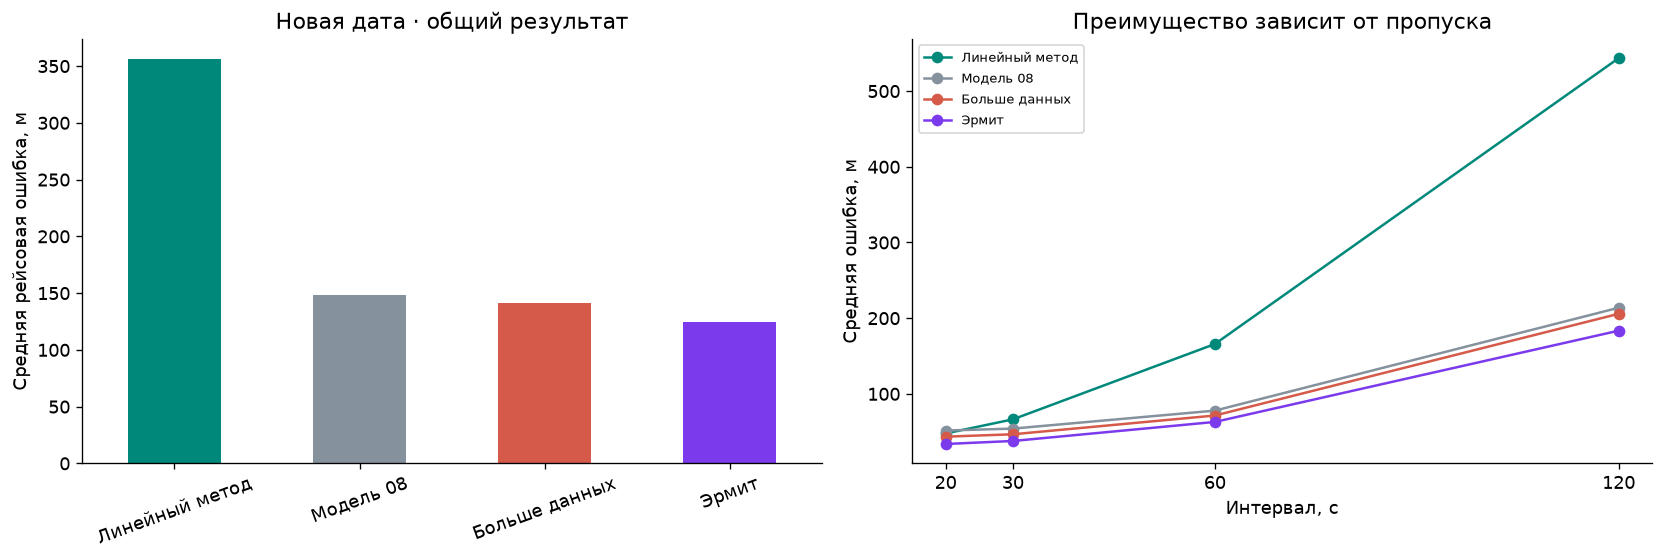

**Влияние дополнительных данных при одинаковой процедуре выбора:** 148.6 → 141.1 м, изменение в пользу расширения **+5.1%**. Исходная модель 08: 148.6 м, линейный метод: 356.1 м.

464

In [6]:
labels = {'linear_lat_lon':'Линейный метод','ridge_08':'Модель 08',
          'ridge_six_new_validation':'6 рейсов · новая validation',
          'ridge_expanded':'Больше данных','hermite':'Эрмит'}
colors = {'linear_lat_lon':'#00897B','ridge_08':'#85929E','ridge_expanded':'#D65A4A','hermite':'#7C3AED'}
fig,axes = plt.subplots(1,2,figsize=(14,4.8))
selected = ['linear_lat_lon','ridge_08','ridge_expanded','hermite']
macro.loc[selected,'mean_m'].rename(index=labels).plot.bar(ax=axes[0],color=[colors[m] for m in selected])
axes[0].set(ylabel='Средняя рейсовая ошибка, м',xlabel='',title='Новая дата · общий результат')
axes[0].tick_params(axis='x',rotation=20)
for method in selected:
    axes[1].plot(gap.index,gap[method],'o-',color=colors[method],label=labels[method])
axes[1].set(xlabel='Интервал, с',ylabel='Средняя ошибка, м',title='Преимущество зависит от пропуска',xticks=gap.index)
axes[1].legend(fontsize=8)
plt.tight_layout()
fig.savefig(study/'figures/11_expanded_training.png',dpi=180)
plt.show()
six = float(macro.loc['ridge_six_new_validation','mean_m'])
expanded = float(macro.loc['ridge_expanded','mean_m'])
old = float(macro.loc['ridge_08','mean_m'])
linear = float(macro.loc['linear_lat_lon','mean_m'])
change = 100*(six-expanded)/six
display(Markdown(f'**Влияние дополнительных данных при одинаковой процедуре выбора:** '
                 f'{six:.1f} → {expanded:.1f} м, изменение в пользу расширения **{change:+.1f}%**. '
                 f'Исходная модель 08: {old:.1f} м, линейный метод: {linear:.1f} м.'))
# Сохраняем все результаты, включая ухудшения и сильный простой ориентир
summary.to_csv(study/'reports/11_test_by_flight.csv',index=False)
macro.to_csv(study/'reports/11_test_macro.csv')
gap.to_csv(study/'reports/11_test_by_gap.csv')
evaluation.to_csv(study/'data/expanded_training/11_test_errors.csv',index=False)
pd.DataFrame(provenance).to_csv(study/'reports/11_data_inventory.csv',index=False)
assert hashlib.sha256(old_model_path.read_bytes()).hexdigest() == plan['old_model_sha256']
result = {'test_day':plan['test_day'],'train_flights':int(tasks.loc[train_mask,'flight_id'].nunique()),
          'validation_flights':int(tasks.loc[val_mask,'flight_id'].nunique()),
          'test_flights':int(tasks.loc[test_mask,'flight_id'].nunique()),
          'train_tasks':int(train_mask.sum()),'test_tasks':int(test_mask.sum()),
          'six_refit_mean_m':six,'expanded_mean_m':expanded,'old08_mean_m':old,
          'linear_mean_m':linear,'hermite_mean_m':float(macro.loc['hermite','mean_m']),
          'improvement_from_more_data_percent':change,'final_alpha':final_model['alpha'],
          'old_model_unchanged':True}
(study/'reports/11_expanded_audit.json').write_text(json.dumps(result,ensure_ascii=False,indent=2)+'\n',encoding='utf8')

## Границы вывода

Это сравнение одной модели с разным объемом данных, при фиксированных признаках и одной новой дате проверки. Объем меняется вместе с разнообразием дат и рейсов; отделить эти эффекты полностью данный эксперимент не позволяет. Отдельные строки зависимы из-за перекрывающихся окон. Средние рейсовых медиан и P95 не являются показателями объединенного распределения.

Если простой метод Эрмита лучше, улучшение относительно линейной интерполяции само по себе не доказывает необходимость ML. Если расширение данных не помогает, это ограничение текущей модели и признаков, а не доказательство бесполезности данных вообще. Настройка после просмотра этого test потребует новой проверки.

Проверочный ответ – наблюдение OpenSky, а не независимая истинная позиция. Разделение по датам и полетам не является разделением по бортам. Аэропорты EGCC/EPWA и часы близки к прежним опытам. Расхождение 43 км остается самостоятельной нерешенной задачей.